# 03 - Heart disease: model training and evaluation

**MedIntel AI | Educational research prototype**

Classify recorded disease presence in the official UCI processed Cleveland
cohort. `num=0` maps to absence; `num=1-4` maps to presence. This is not
prediction of future disease onset or a validated clinical diagnostic system.

## Learning objectives

- Reuse the exact Phase 2 split and preprocessing through Python modules.
- Compare Logistic Regression, Random Forest, and XGBoost on training folds.
- Choose using a predeclared recall-prioritized rule and inspect overfitting.
- Evaluate one selected pipeline on the fixed 61-record holdout.
- Interpret discrimination, classification errors, calibration, and uncertainty.
- Save and reload the full pipeline and verify repeatable research outputs.

## Run instructions and sources

Install `requirements.txt` using the project's Python environment. It applies
the tested `constraints.txt` snapshot. Open this notebook from the root or
`notebooks/`, select that environment, and run all cells in order.

On the first run, `run_experiment` trains all three candidates in cross-validation,
fits only the selected candidate on all training rows, evaluates that selected
fit on the holdout once, and saves aggregate results. Later notebook runs verify
and reuse the saved experiment. They do not silently retrain or reevaluate it.
Changed code, data, package versions, or artifacts cause an explicit error.

Dataset: Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1989).
*Heart Disease* [Dataset]. UCI Machine Learning Repository.
[DOI](https://doi.org/10.24432/C52P4X),
[dataset page](https://archive.ics.uci.edu/dataset/45/heart+disease),
[official input](https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data).
Cleveland data collection: Robert Detrano, Cleveland Clinic Foundation.
UCI lists the data under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

## 1. Import the reusable implementation

**What and why:** Find the project root and import the modules from `src/`.
Notebooks do not export Python objects to each other, so we use fresh builders
instead of relying on hidden variables from notebook 02. The root lookup works
when the kernel starts inside `notebooks/` or the project root.

**Parameters and expected output:** `PROJECT_ROOT` identifies the folder with
`requirements.txt` and the local input. `display`, `Markdown`, and `Image` render
saved tables and figures. Expect a printed project path; nothing is fitted here.

In [1]:
from pathlib import Path
import logging
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    folder for folder in [cwd, *cwd.parents]
    if (folder / "requirements.txt").is_file() and (folder / "src/data_loader.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_heart_data, split_data
from src.model_utils import load_pipeline, predict_records
from src.train import SELECTION_RULE, build_models, load_experiment_report, run_experiment, select_model

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
print(f"Project: {PROJECT_ROOT}")

Project: C:\MedIntel-AI


## 2. Reproduce the source and Phase 2 split

**What and why:** `load_heart_data` checks the original file's SHA-256 and maps
the target. `split_data` uses the established seed 42, 20% test fraction, and
stratification. No raw input is changed and no preprocessing is fitted here.

**Expected output:** 242 training records, 61 test records, and 13 raw features.
The split table checks positive and negative counts and index alignment. These
counts audit allocation; holdout feature values and scores are not inspected
to choose configurations. Preprocessing stays inside each model pipeline.

In [2]:
X, y = load_heart_data(PROJECT_ROOT / "data/raw/processed.cleveland.data")
X_train, X_test, y_train, y_test = split_data(X, y)
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
display(pd.DataFrame({
    "records": [len(X_train), len(X_test)],
    "recorded_absent": [int(y_train.eq(0).sum()), int(y_test.eq(0).sum())],
    "recorded_present": [int(y_train.sum()), int(y_test.sum())],
}, index=["train", "test"]))

,records,recorded_absent,recorded_present
train,242,131,111
test,61,33,28


## 3. Understand the three fixed candidates

**Logistic Regression:** A weighted sum of transformed inputs becomes log-odds;
a sigmoid maps that value into a binary model score. Coefficient signs describe
conditional associations in that fitted representation. For scaled measurements,
one unit corresponds to a training standard deviation. Full one-hot coding and
correlated inputs make individual coefficients dependent on the representation;
do not interpret them as causal effects. L2 regularization shrinks coefficients.
`C=1` sets its inverse strength; smaller C means more shrinkage. `max_iter=2000`
allows convergence. Balanced class weights are learned within each training fit.
It is a compact, interpretable baseline but cannot capture arbitrary nonlinear
interactions without explicitly adding them.
[Reference](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression).

**Random Forest:** Each tree partitions features through decision rules. Each
tree sees a bootstrap sample (sampling records with replacement) and considers
random feature subsets at splits. Averaging trees' class scores reduces the
instability of an individual tree. We use 200 trees, maximum depth 4, at least
3 samples per leaf, and balanced class weights. It can learn nonlinear effects
and interactions, but is less directly interpretable than Logistic Regression
and can still overfit this small sample. Randomizing trees is ensemble learning;
trees do not successively correct each other's residuals.
[Reference](https://scikit-learn.org/stable/modules/ensemble.html#forest).

**XGBoost:** Boosting adds shallow trees sequentially. Each new tree follows
gradients of the current classification loss to improve the ensemble. A small
learning rate limits each step, while depth and leaf constraints plus a weight
penalty control complexity. We use 150 trees, depth 2, learning rate 0.05,
`min_child_weight=3`, `reg_lambda=2`, and 90% row/feature sampling. This can work
well on structured data, but extra flexibility also risks fitting noise.
`tree_method="hist"` uses efficient histogram splits. No early stopping set or
hyperparameter search is used, so no validation/holdout data enters fitting.
[Reference](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBClassifier).

**Code explanation:** Print the actual configurations from `build_models` to
make the experiment reviewable. Seed 42 and a single worker support repeatability.
The same Phase 2 measurement scaling is retained in all pipelines for consistent
feature construction; tree models do not need scaling. These are unfitted objects.

In [3]:
candidates = build_models()
for name, pipeline in candidates.items():
    print(name)
    print(pipeline.named_steps["classifier"])
    print()

Logistic Regression
LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)

Random Forest
RandomForestClassifier(class_weight='balanced', max_depth=4, min_samples_leaf=3,
                       n_estimators=200, n_jobs=1, random_state=42)

XGBoost
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=3, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=150, n_jobs=1,
      

## 4. Declare the evaluation and selection rules before results

Five stratified folds split only the 242 training records. Within each fold,
a fresh full pipeline learns medians, modes, scaling, category vocabulary, and
classifier parameters from the fold's training rows. `cross_validate` reports
validation accuracy, precision, recall, F1, ROC-AUC, and Brier score, plus training
scores for an overfitting check. The same shuffled folds (seed 42) are used for
all candidates. SD is the sample standard deviation across five folds, not a
confidence interval or evidence of clinical reliability.

The predeclared rule chooses highest mean recall among candidates with mean
precision at least 0.60, then F1 and ROC-AUC break ties. The 0.60 guardrail is a
research heuristic to avoid pursuing recall with excessive false positives,
not a clinical acceptance threshold. If all candidates fail it, the documented
fallback maximizes F1. Exact ties retain original candidate order, favoring the
simpler baseline. A score above 0.5 gives class 1. No threshold optimization,
calibration fit, or hyperparameter search is performed.

**Code explanation:** Show the rule, then run the reusable orchestrator once,
or validate and load a previously completed run. It freezes selection from CV
before its only final holdout inference. Aggregate CSV/JSON results, six figures,
and the fitted full pipeline are saved locally. Expected output identifies
whether this is a new run and names the model chosen without test-based revision.
[CV reference](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html).

In [4]:
print(SELECTION_RULE)
report_path = PROJECT_ROOT / "reports/metrics/experiment.json"
if report_path.exists():
    report = load_experiment_report(PROJECT_ROOT)
    print("Verified and reused the completed experiment; no holdout reevaluation.")
else:
    report = run_experiment(PROJECT_ROOT)
    print("Completed a new fixed experiment with one final holdout evaluation.")
print("Selected from training CV:", report["selected_model"])

INFO: Five-fold training comparison: Logistic Regression


Among models with mean CV precision >= 0.60, maximize mean recall; break ties by F1, ROC-AUC, then original order (Logistic Regression first). If none meet 0.60, maximize F1 then recall and ROC-AUC. Threshold 0.5 is fixed; no test-based tuning.


INFO: Five-fold training comparison: Random Forest


INFO: Five-fold training comparison: XGBoost


INFO: Selection frozen from training CV: Logistic Regression


INFO: Saved aggregate report and full pipeline; no patient prediction rows exported.


Completed a new fixed experiment with one final holdout evaluation.
Selected from training CV: Logistic Regression


## 5. Compare observed cross-validation performance

**Code explanation:** Read the actual comparison from the completed run and
format each metric as mean +/- sample SD. Also show fold-level results and
average training-versus-validation performance. Higher is better for the five
requested classification metrics; **lower is better for Brier score**, which
measures squared score error and reflects both discrimination and calibration.

Interpret precision as the fraction of predicted positives that were recorded
positive, recall as the fraction of recorded positives detected, F1 as their
harmonic mean, and ROC-AUC as ranking discrimination over thresholds. Accuracy
combines both classes and can conceal different error costs. Training scores
above validation scores suggest optimism/overfitting; this is a descriptive
check, not proof from an independent evaluation.

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.855 +/- 0.027,0.873 +/- 0.069,0.810 +/- 0.069,0.837 +/- 0.029,0.902 +/- 0.017
Random Forest,0.806 +/- 0.033,0.802 +/- 0.079,0.783 +/- 0.089,0.786 +/- 0.034,0.900 +/- 0.033
XGBoost,0.793 +/- 0.030,0.780 +/- 0.058,0.774 +/- 0.073,0.774 +/- 0.034,0.884 +/- 0.026


,model,train_accuracy_mean,accuracy_mean,accuracy_gap,train_roc_auc_mean,roc_auc_mean,brier_score_mean
0,Logistic Regression,0.8657,0.8552,0.0105,0.9341,0.9025,0.1215
1,Random Forest,0.8864,0.8055,0.0809,0.9635,0.9002,0.1327
2,XGBoost,0.8926,0.7934,0.0992,0.9686,0.8840,0.1353


,model,fold,accuracy,precision,recall,f1,roc_auc,brier_score,train_accuracy,train_roc_auc
0,Logistic Regression,1,0.8776,0.8400,0.9130,0.8750,0.9197,0.1161,0.8756,0.9344
1,Logistic Regression,2,0.8776,0.9444,0.7727,0.8500,0.9091,0.1124,0.8549,0.9327
2,Logistic Regression,3,0.8542,0.9412,0.7273,0.8205,0.8916,0.1207,0.8711,0.9327
3,Logistic Regression,4,0.8125,0.7826,0.8182,0.8000,0.9126,0.1249,0.8711,0.9337
4,Logistic Regression,5,0.8542,0.8571,0.8182,0.8372,0.8794,0.1334,0.8557,0.9373
5,Random Forest,1,0.8367,0.7778,0.9130,0.8400,0.9532,0.1169,0.8912,0.9589
6,Random Forest,2,0.8367,0.8889,0.7273,0.8000,0.8889,0.1297,0.8964,0.9685
7,Random Forest,3,0.8125,0.8824,0.6818,0.7692,0.8636,0.1409,0.8969,0.9642
8,Random Forest,4,0.7708,0.7200,0.8182,0.7660,0.8986,0.1376,0.8763,0.9638
9,Random Forest,5,0.7708,0.7391,0.7727,0.7556,0.8969,0.1381,0.8711,0.9620


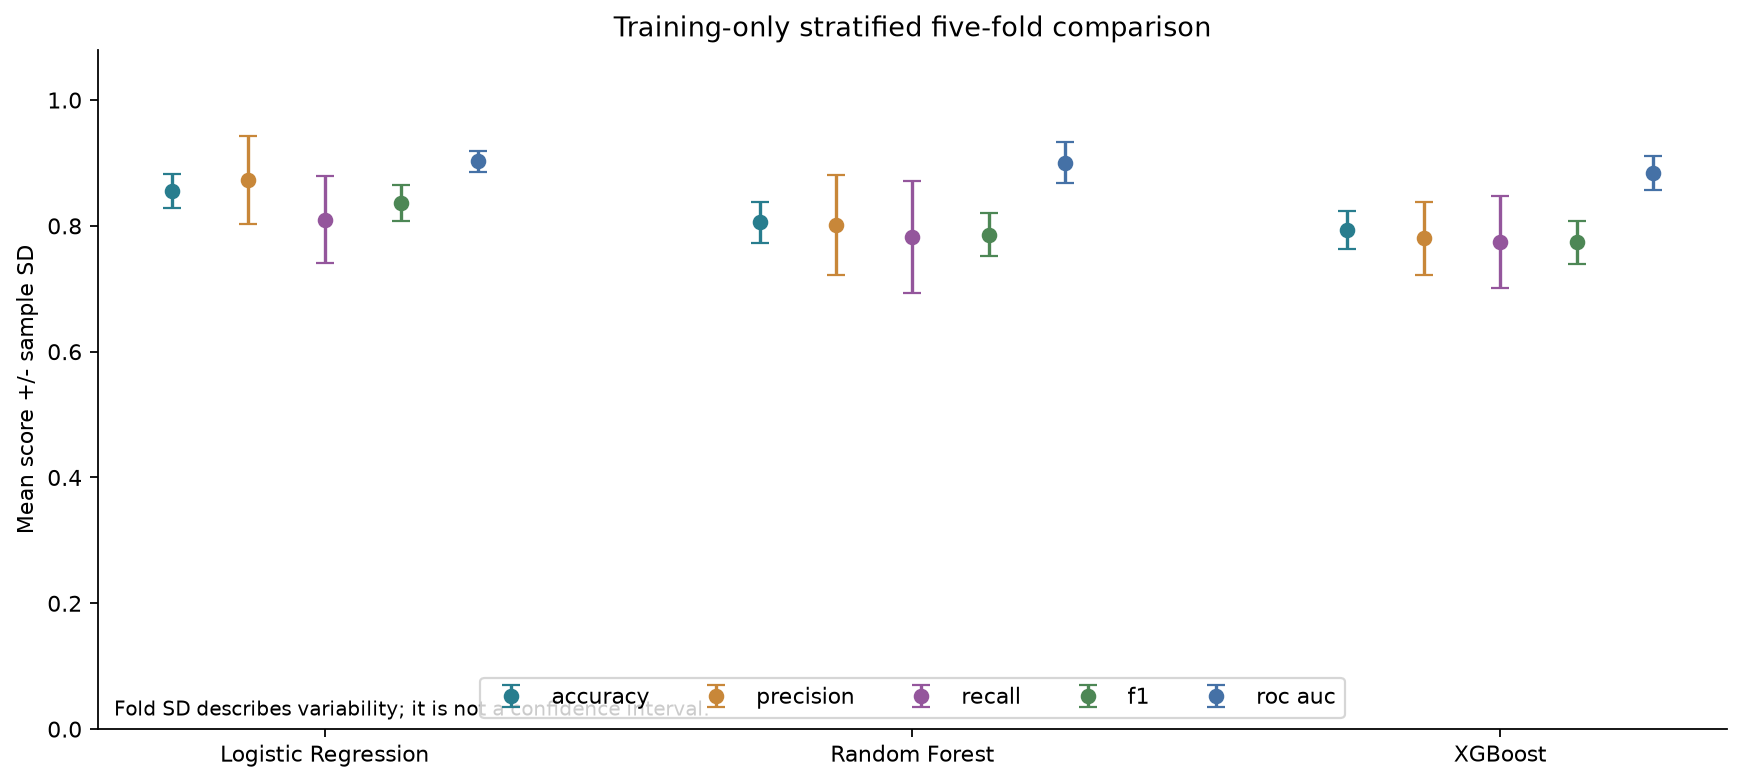

In [5]:
comparison = pd.DataFrame(report["cv_summary"])
formatted = pd.DataFrame({"Model": comparison["model"]})
for metric, label in [("accuracy", "Accuracy"), ("precision", "Precision"), ("recall", "Recall"), ("f1", "F1"), ("roc_auc", "ROC-AUC")]:
    formatted[label] = comparison.apply(lambda row: f"{row[metric + '_mean']:.3f} +/- {row[metric + '_std']:.3f}", axis=1)
display(formatted.set_index("Model"))
display(comparison[["model", "train_accuracy_mean", "accuracy_mean", "accuracy_gap", "train_roc_auc_mean", "roc_auc_mean", "brier_score_mean"]].round(4))
display(pd.read_csv(PROJECT_ROOT / "reports/metrics/cv_folds.csv").round(4))
display(Image(filename=str(PROJECT_ROOT / "reports/figures/cv_comparison.png")))

## 6. Explain selection and alternative priorities

**Code explanation:** Reapply the rule to the saved CV table and assert it
agrees with the frozen model name. Report winners under separate priorities
to make the trade-off explicit. Show the chosen model's recall, precision,
and train/validation accuracy gap. Only these training CV results justify
selection. Close means and overlapping fold variability do not establish
statistical superiority. Precision/recall depend on the fixed threshold.

In [6]:
assert select_model(comparison) == report["selected_model"]
priorities = {metric: comparison.loc[comparison[metric + "_mean"].idxmax(), "model"]
              for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]}
display(pd.Series(priorities, name="Highest observed CV mean").to_frame())
selected_row = comparison.set_index("model").loc[report["selected_model"]]
display(Markdown(
    f"**Frozen choice: {report['selected_model']}.** Mean recall is "
    f"{selected_row['recall_mean']:.3f} and precision is {selected_row['precision_mean']:.3f}. "
    f"The training-minus-validation accuracy gap is {selected_row['accuracy_gap']:.3f}. "
    "The rule prioritizes missed-positive reduction while applying its precision guardrail; "
    "it does not maximize accuracy automatically. The observed gap is an overfitting signal "
    "to report, not a reason to revise the frozen choice using the holdout."
))

,Highest observed CV mean
accuracy,Logistic Regression
precision,Logistic Regression
recall,Logistic Regression
f1,Logistic Regression
roc_auc,Logistic Regression


**Frozen choice: Logistic Regression.** Mean recall is 0.810 and precision is 0.873. The training-minus-validation accuracy gap is 0.011. The rule prioritizes missed-positive reduction while applying its precision guardrail; it does not maximize accuracy automatically. The observed gap is an overfitting signal to report, not a reason to revise the frozen choice using the holdout.

## 7. Read the final held-out evaluation

**Code explanation:** Display the saved metrics from the selected pipeline's
single final inference. This cell does not make new test predictions. Sensitivity
equals positive-class recall. Specificity is the true-negative fraction among
recorded negatives. The classification report includes per-class support.

Wilson 95% intervals summarize binomial uncertainty for accuracy, precision,
sensitivity, and specificity. ROC-AUC uses 500 stratified bootstrap resamples
of the fixed predictions (seed 42), with no refitting. These descriptive
intervals are conditional on this model/sample; they exclude model-selection
uncertainty and population shift. A 61-record test set yields imprecise estimates.
Brier score is also compared with a constant score learned from training prevalence.

In [7]:
evaluation = report["evaluation"]
display(pd.Series(evaluation["metrics"], name="Holdout value").to_frame().round(4))
display(pd.DataFrame({label: values for label, values in evaluation["classification_report"].items() if isinstance(values, dict)}).T.round(4))
intervals = pd.DataFrame(evaluation["intervals_95"], index=["lower", "upper"]).T
display(intervals.rename_axis("Metric").round(4))
print(evaluation["uncertainty_method"])
print("Training-prevalence constant-score Brier baseline:", round(evaluation["training_prevalence_baseline_brier"], 4))

,Holdout value
accuracy,0.8689
precision,0.8125
recall,0.9286
f1,0.8667
roc_auc,0.9665
sensitivity,0.9286
specificity,0.8182
brier_score,0.0832


,precision,recall,f1-score,support
recorded_absent,0.9310,0.8182,0.8710,33.0
recorded_present,0.8125,0.9286,0.8667,28.0
macro avg,0.8718,0.8734,0.8688,61.0
weighted avg,0.8766,0.8689,0.8690,61.0


,lower,upper
Metric,,
accuracy,0.7620,0.9320
precision,0.6469,0.9111
sensitivity,0.7735,0.9802
specificity,0.6561,0.9139
roc_auc,0.9237,0.9968


Wilson binomial intervals; ROC-AUC: 500 stratified percentile bootstrap resamples, seed 42. Descriptive, conditional on this fitted model and small sample; excludes selection and dataset-shift uncertainty.
Training-prevalence constant-score Brier baseline: 0.2483


## 8. Interpret the confusion matrix

**Code explanation:** Show the exported count heatmap and calculate its four
cells from the saved matrix. Rows are recorded classes and columns are predicted
classes; class 1 means recorded disease presence. False negatives are recorded
positives assigned class 0; false positives are recorded negatives assigned
class 1. These are research classification errors, not confirmed clinical
diagnoses. The counts explain why high accuracy alone can hide missed positives.

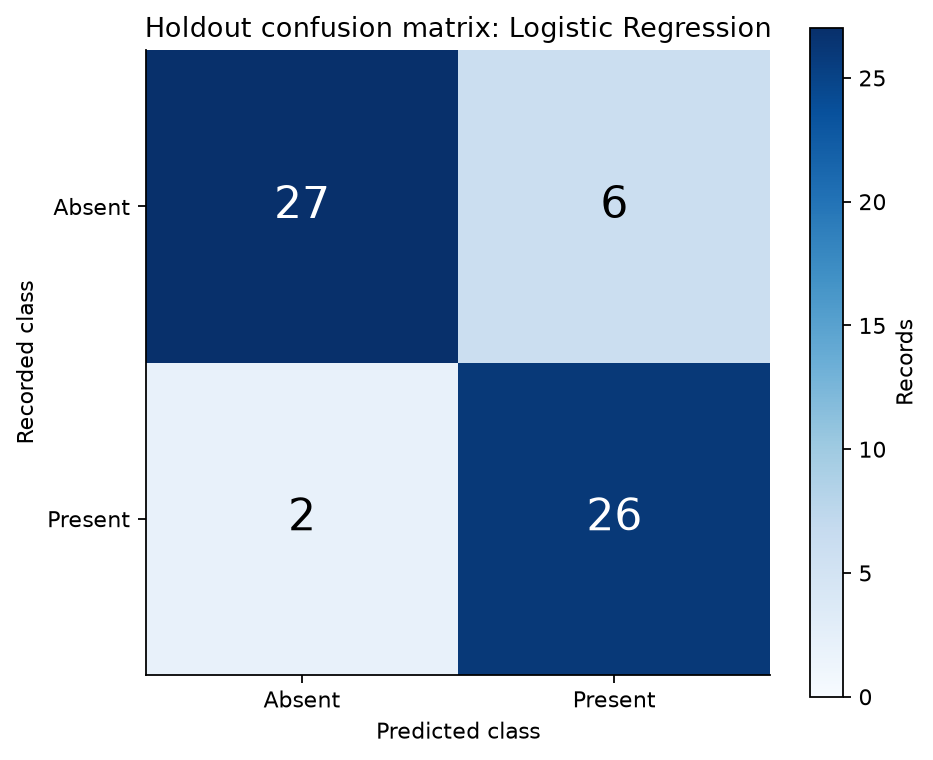

**TN=27, FP=6, FN=2, TP=26.** Of 28 recorded-positive holdout records, 2 were missed. Of 33 recorded-negative records, 6 were assigned class 1. The selection remains unchanged.

In [8]:
display(Image(filename=str(PROJECT_ROOT / "reports/figures/confusion_matrix.png")))
(tn, fp), (fn, tp) = evaluation["confusion_matrix"]
display(Markdown(f"**TN={tn}, FP={fp}, FN={fn}, TP={tp}.** Of {tp + fn} recorded-positive "
                 f"holdout records, {fn} were missed. Of {tn + fp} recorded-negative records, "
                 f"{fp} were assigned class 1. The selection remains unchanged."))

## 9. Interpret ranking, score overlap, and calibration

**Code explanation:** Display four saved figures from the same holdout
predictions. No new evaluation or tuning happens in this display cell.

- **ROC:** sensitivity versus false-positive rate across score thresholds;
  AUC describes ranking, not calibration or clinical benefit.
- **Precision-recall:** how positive-class precision changes with recall.
  The reference line is this sample's positive fraction, not population prevalence.
- **Score distribution:** overlap between recorded classes exposes ambiguity.
  The dashed line marks the fixed 0.5 threshold. Scores are uncalibrated model
  outputs, not real-world disease probabilities.
- **Calibration:** mean scores versus observed positive fractions in five
  fixed-width bins. Counts and Wilson intervals expose sparse-bin uncertainty.
  A curve near the diagonal on this tiny test set cannot establish reliability.
  We assess calibration; we do not fit a calibrator using these test labels.

[Calibration reference](https://scikit-learn.org/stable/modules/calibration.html).

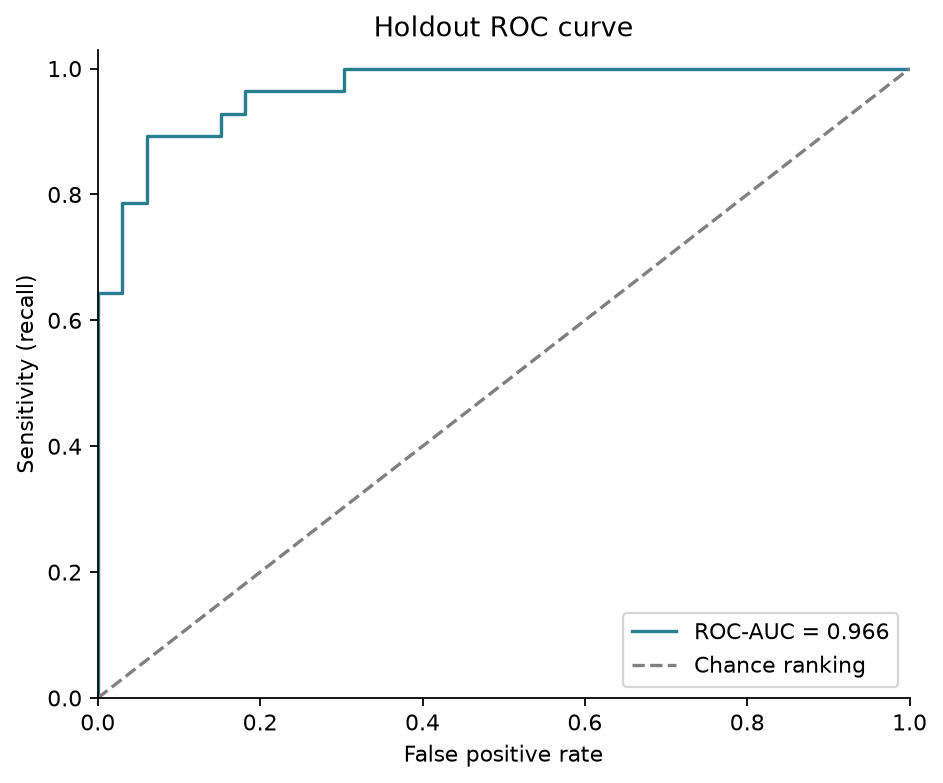

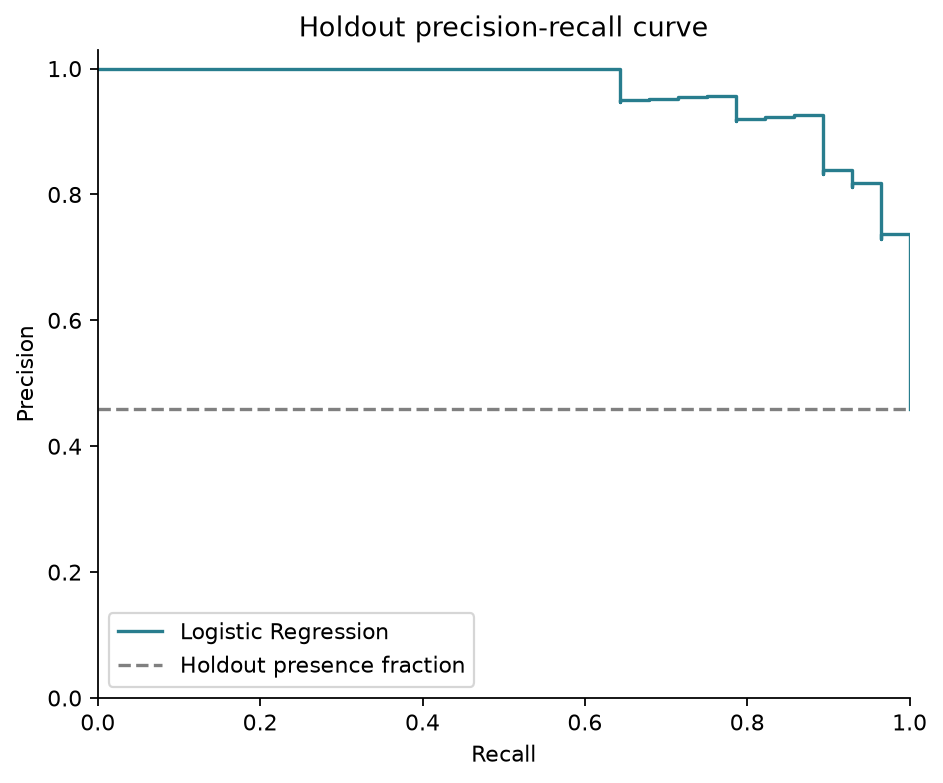

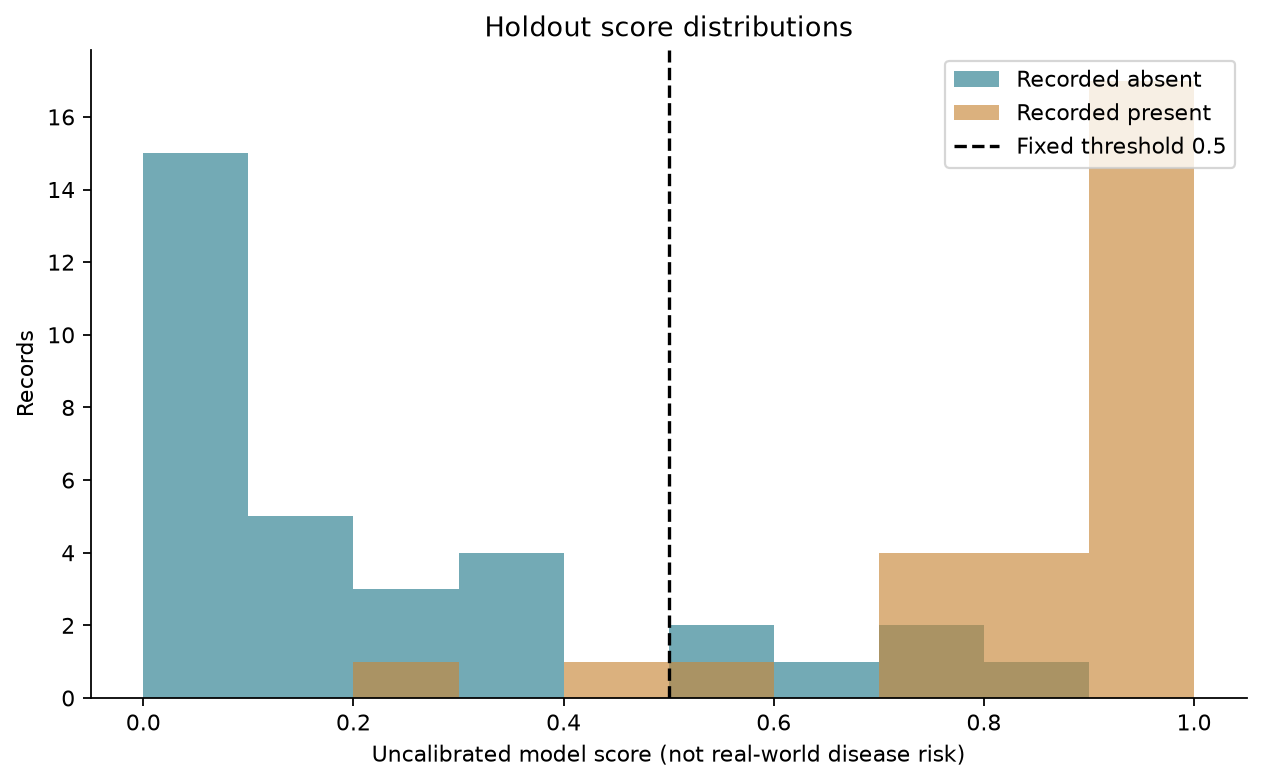

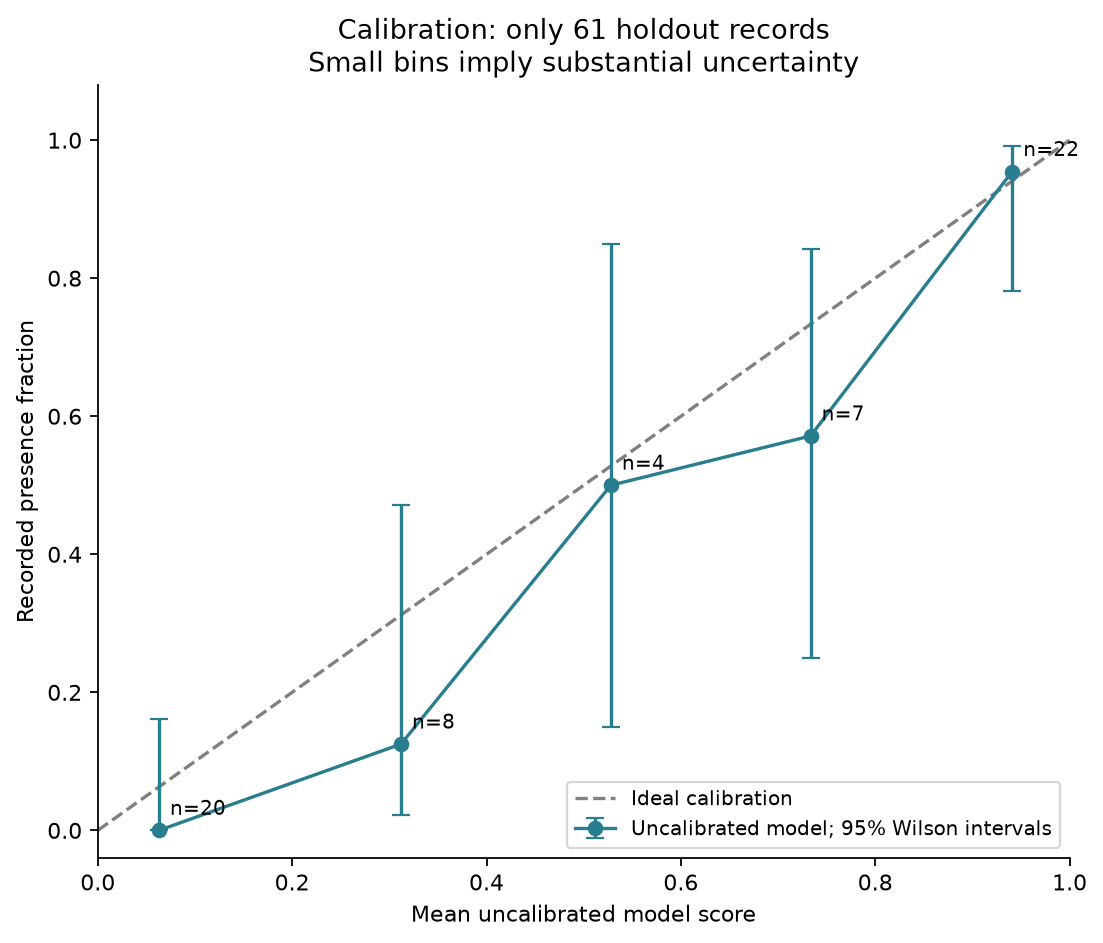

In [9]:
for name in ["roc_curve", "precision_recall_curve", "score_distribution", "calibration_curve"]:
    display(Image(filename=str(PROJECT_ROOT / "reports/figures" / f"{name}.png")))

## 10. Verify persistence using training rows

**Code explanation:** Load the local pipeline with explicit trust and the hash
recorded in the experiment manifest. Joblib loading can execute code: a matching
hash only verifies consistency with this manifest and does not make an unknown
artifact safe. The saved object includes both preprocessing and classification.

Inspect its feature names and compare the reusable validated prediction utility
with its direct scores on three **training** records. Do not make another
holdout evaluation. The utility requires all 13 field names, allows explicit
null values for imputation, reorders columns, and rejects invalid codes,
infinities, entirely empty records, or target fields. Display only confirmation
and transformed feature count, without exporting individual input rows/scores.

In [10]:
restored = load_pipeline(
    PROJECT_ROOT / report["artifact"], trusted=True,
    expected_sha256=report["generated_file_hashes"][report["artifact"]],
)
outputs = predict_records(restored, X_train.iloc[:3])
np.testing.assert_allclose([row["model_score"] for row in outputs], restored.predict_proba(X_train.iloc[:3])[:, 1])
assert len(restored.named_steps["preprocessor"].get_feature_names_out()) == 28
print("Trusted full pipeline reloaded; validated utility scores match direct scores on training inputs.")
print("Expected transformed feature count: 28")
print("Artifact:", report["artifact"])
print("Reports: reports/metrics; figures: reports/figures")

Trusted full pipeline reloaded; validated utility scores match direct scores on training inputs.
Expected transformed feature count: 28
Artifact: models/heart_disease_pipeline.joblib
Reports: reports/metrics; figures: reports/figures


## Limitations and conclusion

This fixed experiment supplies a reproducible research baseline, not a clinical
claim. Only 303 historical records are available, and the final test set has
28 recorded positives and 33 negatives. Results are sensitive to sampling,
cohort composition, diagnostic practices, and feature availability.

The earlier exploration used the full cohort, so this holdout is not an
independent external validation cohort. The source has no usable patient IDs
or chronology for patient-group or temporal validation. Diagnostic features
such as vessel imaging and thallium-test results may be unavailable at the
intended decision time for a future application. Performance and calibration
need independent, appropriate evaluation before any broader interpretation.

Cross-validation variability and descriptive holdout intervals do not include
all sources of uncertainty. The precision guardrail and 0.5 score threshold are
research choices, not medical thresholds. Associations are not causal effects.
Class weighting and sampling also affect score interpretation. No calibrated
real-world risk estimates are claimed.

Automated tests cover target mapping, the preserved split, fold-local fitting,
missingness, schema stability, selection logic, input validation, fixed-seed
repeatability, metrics, and serialization. Run `python -m pytest -q` from the root.

The actual comparison and holdout results above complete Phase 3. The reusable
pipeline, provenance manifest, and figures are available locally. Phase 4 SHAP,
any API/frontend, and other disease/imaging modules require later approval.